# Transformers


#### A Transformer is a deep learning architecture designed to process sequences of text using self-attention.

- Transformers are the foundation of many modern NLP models, including BERT, GPT, and T5.

- Before Transformers, we used models such as RNNs and LSTMs for NLP tasks.

<img src="https://drive.google.com/thumbnail?id=1unPqGaKftHxp37-F99Bg6hJzFbQdCGC7&sz=w1000" width="700">

In [1]:
%pip -q install transformers torch matplotlib

Note: you may need to restart the kernel to use updated packages.


## 1. Load a Transformer

We use **DistilBERT**, a  Transformer fine-tuned for positive/negative sentiment classification.

In [2]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

model_name = "distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(model_name, attn_implementation="eager")
model.eval()

# Look inside the Transformer architecture.
print("Transformer layers:", model.config.n_layers)
print("Attention heads per layer:", model.config.n_heads)
print("Hidden size:", model.config.dim)

C:\Users\ezio9\Documents\Codex\2026-11-10\i-x20\work\python_packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\ezio9\Documents\Codex\2026-11-10\i-x20\work\python_packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ezio9\Documents\Codex\2026-11-10\i-x20\work\huggingface\hub\models--distilbert-base-uncased-finetuned-sst-2-english. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Transformer layers: 6
Attention heads per layer: 12
Hidden size: 768



<img src="https://drive.google.com/thumbnail?id=1v2dRK1KR_ydZOknjj8Xv8_wjOdXleDYs&sz=w1000" width="500">

## 2. Tokenizing the text

In [3]:
sentence = "The movie was not good."

# Tokenization: converts text into token IDs
inputs = tokenizer(sentence, return_tensors="pt")

# [CLS] = start token, [SEP] = end token
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

print("Tokens:", tokens)

Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']


## 3. Embeddings and self-attention

Each token ID becomes a **vector (embedding)**. Inside each Transformer layer, **self-attention** lets a token use information from other tokens in the same sentence.

In [4]:
import torch

# Enable attention weights
# Eager attention was selected when loading the model.

with torch.no_grad():
    embeddings = model.distilbert.embeddings(inputs["input_ids"])
    outputs = model(**inputs, output_attentions=True)

# Attention from the first layer and first head
attention = outputs.attentions[0][0, 0]

print("Embeddings shape:", embeddings.shape)
print("Attention shape:", attention.shape)
print("Tokens:", tokens)
print("Attention weights:\n", attention)

Embeddings shape: torch.Size([1, 8, 768])
Attention shape: torch.Size([8, 8])
Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']
Attention weights:
 tensor([[0.1145, 0.0938, 0.0681, 0.0701, 0.0596, 0.0800, 0.1593, 0.3546],
        [0.4147, 0.0793, 0.0481, 0.1018, 0.1084, 0.0805, 0.0789, 0.0883],
        [0.1634, 0.0327, 0.0975, 0.0403, 0.1819, 0.1402, 0.0866, 0.2574],
        [0.2882, 0.1014, 0.0504, 0.0669, 0.2180, 0.1009, 0.1231, 0.0511],
        [0.3612, 0.0501, 0.0696, 0.1200, 0.0642, 0.1304, 0.0953, 0.1092],
        [0.3065, 0.0469, 0.1175, 0.1915, 0.0630, 0.0555, 0.1120, 0.1071],
        [0.3505, 0.0935, 0.0572, 0.0753, 0.0972, 0.0964, 0.1165, 0.1135],
        [0.3513, 0.1019, 0.0318, 0.0541, 0.1036, 0.0607, 0.0755, 0.2210]])


## 4. Classification: From Transformer to prediction

The Transformer produces contextual representations. The **classification head** turns them into two scores (*logits*). **Softmax** converts these into probabilities that sum to 1.

In [5]:
# Get prediction scores from the Transformer
with torch.no_grad():
    logits = model(**inputs).logits

# Convert scores into probabilities
probs = torch.softmax(logits, dim=1)[0]

# Display the prediction
prediction = probs.argmax().item()

print("Prediction:", model.config.id2label[prediction])
print("Confidence:", round(probs[prediction].item(), 3))


Prediction: NEGATIVE
Confidence: 1.0



### Task: Exploring Transformer Layers and Attention Heads

Load the pretrained **`bert-base-uncased`** model using Hugging Face Transformers.

1. Write code to print the number of Transformer layers and the number of attention heads per layer.
2. Calculate and print the total number of attention heads across all Transformer layers.
3. Using the sentence `"Transformers use self-attention to understand language."`, extract the attention weights from the **third Transformer layer and second attention head**.
4. Explain what the rows and columns of the attention matrix represent.

## Solution: Exploring BERT layers and attention heads

Load the pretrained BERT encoder in evaluation mode and enable eager attention so that attention probabilities are returned.

In [6]:
from transformers import AutoModel, AutoTokenizer
import torch

bert_name = "bert-base-uncased"
bert_tokenizer = AutoTokenizer.from_pretrained(bert_name)
bert_model = AutoModel.from_pretrained(bert_name, attn_implementation="eager")
bert_model.eval()

num_layers = bert_model.config.num_hidden_layers
heads_per_layer = bert_model.config.num_attention_heads
total_heads = num_layers * heads_per_layer
print("Transformer layers:", num_layers)
print("Attention heads per layer:", heads_per_layer)
print("Total attention heads across all layers:", total_heads)
assert (num_layers, heads_per_layer, total_heads) == (12, 12, 144)

C:\Users\ezio9\Documents\Codex\2026-11-10\i-x20\work\python_packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ezio9\Documents\Codex\2026-11-10\i-x20\work\huggingface\hub\models--bert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Transformer layers: 12
Attention heads per layer: 12
Total attention heads across all layers: 144


In [7]:
bert_sentence = "Transformers use self-attention to understand language."
bert_inputs = bert_tokenizer(bert_sentence, return_tensors="pt")
bert_tokens = bert_tokenizer.convert_ids_to_tokens(bert_inputs["input_ids"][0])

with torch.no_grad():
    bert_outputs = bert_model(**bert_inputs, output_attentions=True)

# Python uses zero-based indices: layer 3 -> 2, head 2 -> 1.
# Each layer's tensor has shape (batch, heads, query tokens, key tokens).
bert_attention = bert_outputs.attentions[2][0, 1].cpu()
print("Indexed tokens:", list(enumerate(bert_tokens)))
print("Layer 3, head 2 attention shape:", tuple(bert_attention.shape))
torch.set_printoptions(precision=4, linewidth=160)
print("Attention weights:\n", bert_attention)
print("Row sums:", bert_attention.sum(dim=-1))
assert bert_attention.shape == (len(bert_tokens), len(bert_tokens))
assert torch.isfinite(bert_attention).all()
assert torch.allclose(bert_attention.sum(dim=-1), torch.ones(len(bert_tokens)), atol=1e-5)

Indexed tokens: [(0, '[CLS]'), (1, 'transformers'), (2, 'use'), (3, 'self'), (4, '-'), (5, 'attention'), (6, 'to'), (7, 'understand'), (8, 'language'), (9, '.'), (10, '[SEP]')]
Layer 3, head 2 attention shape: (11, 11)
Attention weights:
 tensor([[7.3176e-01, 7.9131e-03, 1.0591e-02, 5.5538e-03, 1.6532e-02, 6.8604e-03, 1.0085e-02, 1.1588e-02, 5.5202e-03, 3.8613e-02, 1.5499e-01],
        [8.8883e-01, 4.7016e-03, 3.4382e-02, 1.7840e-04, 2.7377e-03, 5.0542e-03, 9.0185e-04, 7.3192e-04, 4.0114e-04, 5.1106e-03, 5.6975e-02],
        [1.4273e-01, 5.6892e-01, 5.4059e-03, 3.5340e-02, 4.1156e-02, 6.7886e-02, 8.9602e-02, 3.2741e-04, 5.3299e-03, 8.9670e-03, 3.4334e-02],
        [3.3953e-01, 7.3164e-02, 1.5250e-03, 1.6106e-04, 2.0160e-01, 8.1124e-02, 6.3570e-02, 2.5709e-02, 1.6392e-03, 2.8494e-02, 1.8348e-01],
        [1.4291e-01, 6.9677e-02, 7.1289e-02, 6.3943e-01, 1.2104e-02, 1.2819e-02, 3.4381e-03, 2.5649e-03, 1.4182e-02, 9.2673e-03, 2.2316e-02],
        [1.1261e-01, 5.4484e-01, 1.1556e-02, 2.0262

### What the attention matrix means

BERT base has **12 Transformer layers**, each with **12 attention heads**, giving **12 × 12 = 144 heads** across the layers.

Each **row** represents a query token: the token whose representation is being updated. Each **column** represents a key token: a token that the query can attend to. Entry `bert_attention[i, j]` is the attention weight from query token `i` to key token `j` in the third layer's second head. A larger value means that token `j` receives more weight when computing the contextual representation for token `i` in this head.

Both axes follow `bert_tokens`, including `[CLS]`, `[SEP]`, punctuation, and any WordPiece subwords. These are token positions, not necessarily whole words. Each row sums to approximately 1 because attention applies softmax over key positions; columns need not sum to 1 and the matrix need not be symmetric. Evaluation mode disables dropout so the displayed row sums retain this property. Attention weights describe this head's information mixing and are not a complete explanation of the model's reasoning.

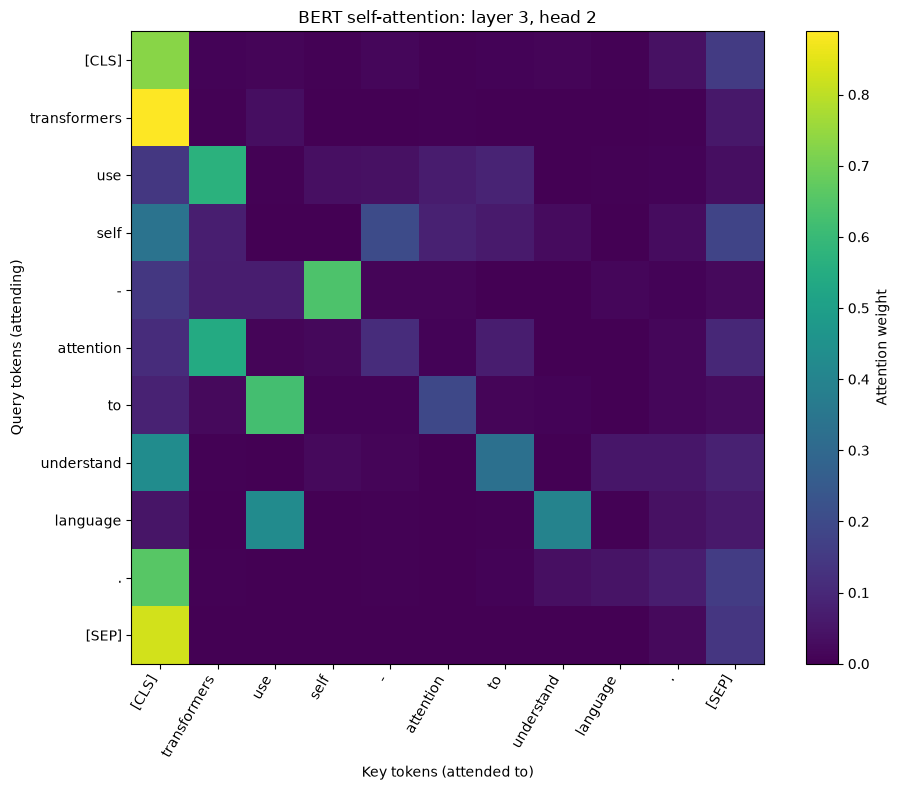

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(bert_attention.numpy(), cmap="viridis", vmin=0)
ax.set_xticks(range(len(bert_tokens)), bert_tokens, rotation=60, ha="right")
ax.set_yticks(range(len(bert_tokens)), bert_tokens)
ax.set_xlabel("Key tokens (attended to)")
ax.set_ylabel("Query tokens (attending)")
ax.set_title("BERT self-attention: layer 3, head 2")
fig.colorbar(image, ax=ax, label="Attention weight")
fig.tight_layout()
plt.show()